# **Part4: Classification**

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/A1_Classification/data/cleaned_data.csv')

## **1. binning the median house value into discrete classes(low, medium, high)**

In [ ]:
# by quantile
low, medium = df['median_house_value'].quantile([1/3, 2/3])

def categorize_value(value):
    if value <= low:
        return 'Low'
    elif value <= medium:
        return 'Medium'
    else:
        return 'High'

# Create the categorical target variable
df['house_value_category'] = df['median_house_value'].apply(categorize_value)

# Encode the target variable
category_mapping = {'Low': 0, 'Medium': 1, 'High': 2}
df['house_value_category'] = df['house_value_category'].map(category_mapping)
df = df.drop(columns=['median_house_value'])
df.to_csv("/content/drive/MyDrive/A1_Classification/data/cleaned_data_classification.csv", index = False)


- Low: Values below the 1/3 quantile.
- Medium: Values between the 1/3 and 2/3 quantile.
- High: Values above the 2/3 quantile.

**Prepare the features and target variable**

In [ ]:
from sklearn.preprocessing import StandardScaler

# Prepare the features and target variable
X = df.drop(columns=['house_value_category'])
y = df['house_value_category']

# Scale the features
scaler = StandardScaler()
X = scaler.fit_transform(X)

## **2. Implement a logistic regression model to predict house_value_category**

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LogisticRegression

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train logistic regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

## **3. Evaluation(confusion matrix, accuracy, precision, recall, and F1-score)**

Confusion Matrix:
 [[981 205  35]
 [221 665 304]
 [ 44 208 954]]
Accuracy: 71.88%
Precision: 0.71
Recall: 0.72
F1 Score: 0.72


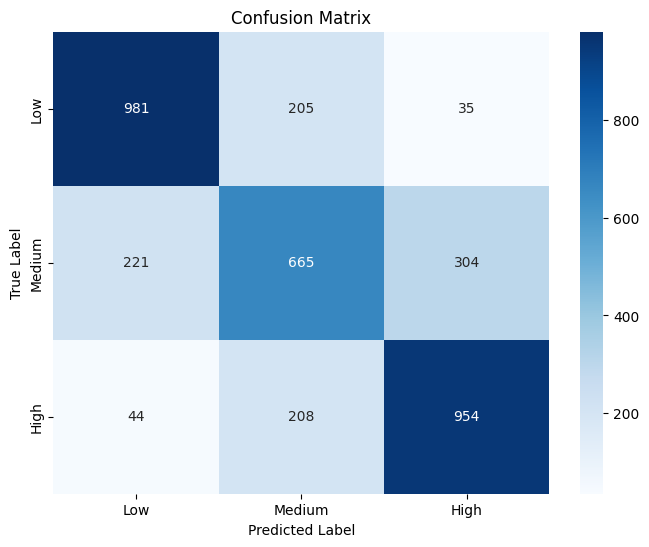

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc

# Evaluation Metrics
conf_matrix = confusion_matrix(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print("Confusion Matrix:\n", conf_matrix)
print("Accuracy: {:.2f}%".format(accuracy * 100))
print("Precision: {:.2f}".format(precision))
print("Recall: {:.2f}".format(recall))
print("F1 Score: {:.2f}".format(f1))

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

**Diagonal Cells (Correct Predictions)**:
- Low Class: 981 instances were correctly classified as "Low".
- Medium Class: 665 instances were correctly classified as "Medium".
- High Class: 954 instances were correctly classified as "High".
**Off-Diagonal Cells (Misclassifications):**
- Low → Medium: 205 instances of "Low" were misclassified as "Medium".
- Low → High: 35 instances of "Low" were misclassified as "High".
- Medium → Low: 221 instances of "Medium" were misclassified as "Low".
- Medium → High: 304 instances of "Medium" were misclassified as "High".
- High → Low: 44 instances of "High" were misclassified as "Low".
- High → Medium: 208 instances of "High" were misclassified as "Medium".

The confusion matrix indicates that the logistic regression model has a strong ability to distinguish Low and High house values but struggles more with the Medium class. This kind of misclassification pattern is common when there is overlap in the feature space between adjacent categories. It might be better using more complex models (like random forests or support vector machines) or adjust feature selection to improve the classification performance, particularly for the Medium class.

## **4. ROC and AUC**

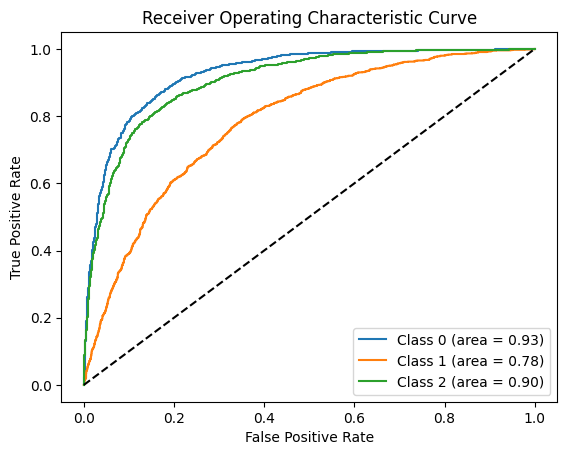

In [ ]:
y_prob = model.predict_proba(X_test)
fpr = {}
tpr = {}
roc_auc = {}

for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_test == i, y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure()
for i in range(3):
    plt.plot(fpr[i], tpr[i], label='Class {} (area = {:.2f})'.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic Curve')
plt.legend(loc='lower right')
plt.show()

This ROC curve analysis is consistent with what was previously observed from the confusion matrix and the evaluation metrics where Class 1 had higher misclassification rate. This may require further regularization.

## **5. k-fold cross-validation**

Cross-validation accuracy scores for each fold: [0.71641791 0.71918187 0.72028745 0.71420674 0.73119469 0.72732301
 0.70132743 0.7505531  0.72400442 0.6875    ]
Mean cross-validation accuracy: 0.72%
Variance of cross-validation accuracy: 0.0003
Standard deviation of cross-validation accuracy: 0.0160


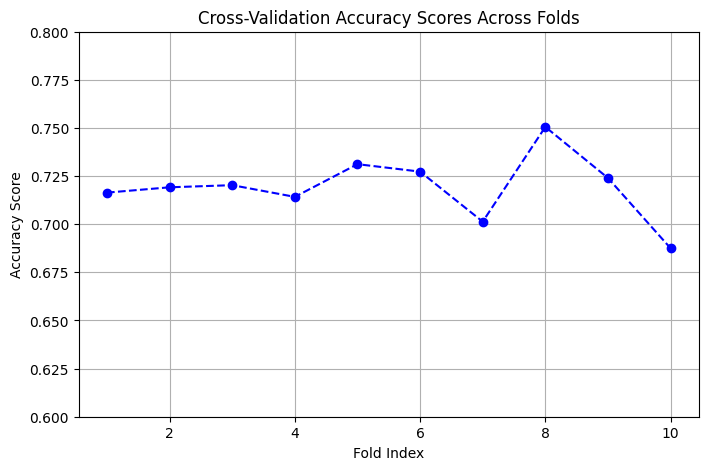

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Perform cross-validation with k-fold
kfold = KFold(n_splits=10, random_state=42, shuffle=True)
cross_val_scores = cross_val_score(model, X, y, cv=kfold, scoring='accuracy')

# Print cross-validation scores for each fold
print("Cross-validation accuracy scores for each fold:", cross_val_scores)

# Calculate and print mean, variance, and standard deviation
mean_cv_score = np.mean(cross_val_scores)
variance_cv_score = np.var(cross_val_scores)
std_cv_score = np.std(cross_val_scores)

print(f"Mean cross-validation accuracy: {mean_cv_score:.2f}%")
print(f"Variance of cross-validation accuracy: {variance_cv_score:.4f}")
print(f"Standard deviation of cross-validation accuracy: {std_cv_score:.4f}")

# Plot cross-validation scores for each fold
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cross_val_scores) + 1), cross_val_scores, marker='o', linestyle='--', color='b')
plt.title('Cross-Validation Accuracy Scores Across Folds')
plt.xlabel('Fold Index')
plt.ylabel('Accuracy Score')
plt.ylim(0.6, 0.8)
plt.grid(True)
plt.show()


The cross-validation accuracy scores for each fold show some variation, but are generally consistent, ranging from 0.6875 to 0.7505. The mean cross-validation accuracy is 0.72, and the variance and standard deviation are very low (0.0003 and 0.0160, respectively), indicating a stable model with little fluctuation across the folds.